# Optimal Sparse Decision Trees with GOSDT

This notebook uses the Pima Indians Diabetes dataset. The goal is to show what changes when the tree is learned by a sparse-tree optimizer.

GOSDT searches over binary features. We first convert a few continuous variables into threshold indicators such as `Glucose >= 140`. This avoids the one-hot encoding problem, where every numeric value becomes its own category.


## Install and load libraries

The example below uses the `gosdt==0.1.8` API.


In [19]:
import importlib
import importlib.metadata
import os
import subprocess
import sys
import tempfile

# Avoid matplotlib cache warnings in restricted notebook runtimes.
os.environ.setdefault("MPLCONFIGDIR", tempfile.mkdtemp(prefix="matplotlib-"))

# This notebook uses the older GOSDT(config) API, so keep the package pinned.
GOSDT_VERSION = "0.1.8"

def installed_version(package_name):
    try:
        return importlib.metadata.version(package_name)
    except importlib.metadata.PackageNotFoundError:
        return None

if installed_version("gosdt") != GOSDT_VERSION:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", f"gosdt=={GOSDT_VERSION}"]
    )
    importlib.invalidate_caches()

# Install gmpy2 as it's a dependency for gosdt and might not be installed automatically
if installed_version("gmpy2") is None:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "gmpy2"]
    )
    importlib.invalidate_caches()

print(f"Using gosdt {installed_version('gosdt')}")

Using gosdt 0.1.8


In [20]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from gosdt import GOSDT
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text


## Load the Diabetes dataset

The target is `Outcome`: `1` means diabetes and `0` means no diabetes. We use a stratified split.


In [21]:
pima_path = Path("pima.csv")
pima = pd.read_csv(pima_path if pima_path.exists() else "https://bit.ly/PimaIDD")

feature_cols = pima.columns.values.tolist()[:-1]
X_raw = pima[feature_cols]
y = pima.Outcome

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw,
    y,
    test_size=0.30,
    random_state=411,
    stratify=y,
)

print(pima.shape)
pima.head()


(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## Discretize continuous features

GOSDT expects discrete/binary inputs. Here we create a small, fixed set of threshold indicators. This is different from one-hot encoding numeric values: each column is a meaningful condition that a tree can use as a rule.

The thresholds are deliberately coarse to keep the search space and the resulting tree small enough for class use.


In [ ]:
THRESHOLDS = {
    "Pregnancies": [1, 3, 6],
    "Glucose": [100, 120, 140, 160],
    "BloodPressure": [70, 80, 90],
    "BMI": [25, 30, 35],
    "DiabetesPedigreeFunction": [0.5, 0.8],
    "Age": [25, 30, 45],
}


def threshold_name(feature, threshold):
    safe_threshold = str(threshold).replace(".", "_")
    return f"{feature}_ge_{safe_threshold}"


def make_threshold_features(X):
    columns = {}
    for feature, thresholds in THRESHOLDS.items():
        for threshold in thresholds:
            columns[threshold_name(feature, threshold)] = (X[feature] >= threshold).astype(int)
    return pd.DataFrame(columns, index=X.index)


X_train = make_threshold_features(X_train_raw)
X_test = make_threshold_features(X_test_raw)

print(f"Binary features: {X_train.shape[1]}")
X_train.head()


In [22]:
pd.DataFrame(
    {
        "feature": X_train.columns,
        "train_prevalence": X_train.mean().round(3),
    }
).sort_values("feature")


,feature,train_prevalence
Age_ge_25,Age_ge_25,0.704
Age_ge_30,Age_ge_30,0.479
Age_ge_45,Age_ge_45,0.173
BMI_ge_25,BMI_ge_25,0.849
BMI_ge_30,BMI_ge_30,0.605
BMI_ge_35,BMI_ge_35,0.320
BloodPressure_ge_70,BloodPressure_ge_70,0.581
BloodPressure_ge_80,BloodPressure_ge_80,0.259
BloodPressure_ge_90,BloodPressure_ge_90,0.074
DiabetesPedigreeFunction_ge_0_5,DiabetesPedigreeFunction_ge_0_5,0.350


## Train a bounded GOSDT model

For GOSDT, `regularization` is a tree-complexity penalty. It is not L1/L2 regularization on linear coefficients. Larger values favor fewer leaves; smaller values allow a more detailed tree.

In [23]:
gosdt_config = {
    "regularization": 0.002,
    "depth_budget": 3,
    "time_limit": 30,
    "similar_support": False,
}

gosdt = GOSDT(gosdt_config)
_ = gosdt.fit(X_train, y_train)


gosdt reported successful execution
training completed. 0.000/0.000/0.013 (user, system, wall), mem=0 MB
bounds: [0.225877..0.225877] (0.000000) loss=0.217877, iterations=37


In [24]:
print("GOSDT tree")
print(gosdt.tree)

print(f"Training accuracy: {gosdt.score(X_train, y_train):.3f}")
print(f"Test accuracy: {gosdt.score(X_test, y_test):.3f}")
print(f"Nodes: {gosdt.nodes()}")
print(f"Leaves: {gosdt.leaves()}")
print(f"Max depth: {gosdt.max_depth()}")
print(f"Training user time: {getattr(gosdt, 'utime', np.nan):.3f} seconds")


GOSDT tree
if BMI_ge_30 = 1 and Glucose_ge_140 = 1 then:
    predicted class: 1
    misclassification penalty: 0.041
    complexity penalty: 0.002

else if BMI_ge_30 = 1 and Glucose_ge_140 != 1 then:
    predicted class: 0
    misclassification penalty: 0.121
    complexity penalty: 0.002

else if BMI_ge_30 != 1 and Glucose_ge_160 = 1 then:
    predicted class: 1
    misclassification penalty: 0.009
    complexity penalty: 0.002

else if BMI_ge_30 != 1 and Glucose_ge_160 != 1 then:
    predicted class: 0
    misclassification penalty: 0.047
    complexity penalty: 0.002
Training accuracy: 0.782
Test accuracy: 0.710
Nodes: 7
Leaves: 4
Max depth: 3
Training user time: 0.000 seconds


## Evaluate GOSDT

`GOSDT.predict` returns hard class labels. A ROC curve needs a score, not just a class label. Since this package version does not expose `predict_proba`, we use the diabetes rate of the training leaf as a simple score for every test instance that falls into that leaf.


Accuracy:  0.710
Precision: 0.646
Recall:    0.383
ROC AUC using leaf rates: 0.706


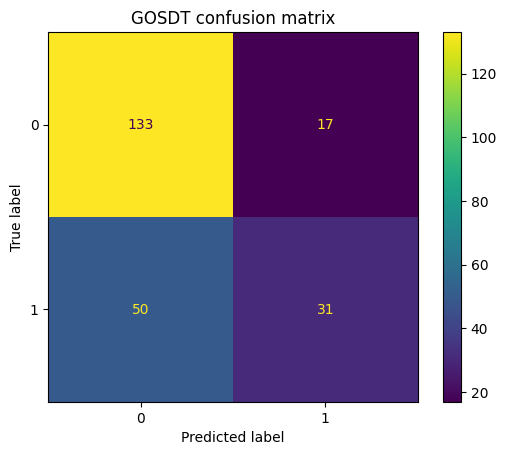

In [25]:
gosdt_pred = gosdt.predict(X_test)
gosdt_leaf_score = test_paths.map(leaf_summary["diabetes_rate"]).to_numpy()

print(f"Accuracy:  {metrics.accuracy_score(y_test, gosdt_pred):.3f}")
print(f"Precision: {metrics.precision_score(y_test, gosdt_pred):.3f}")
print(f"Recall:    {metrics.recall_score(y_test, gosdt_pred):.3f}")
print(f"ROC AUC using leaf rates: {metrics.roc_auc_score(y_test, gosdt_leaf_score):.3f}")
metrics.ConfusionMatrixDisplay.from_predictions(y_test, gosdt_pred)
plt.title("GOSDT confusion matrix")
plt.show()


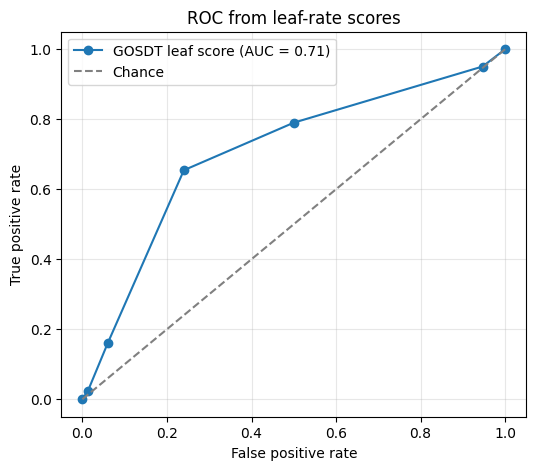

,threshold,fpr,tpr
0,inf,0.000000,0.000000
1,0.900000,0.013333,0.024691
2,0.742857,0.060000,0.160494
3,0.702128,0.240000,0.654321
4,0.204918,0.500000,0.790123
5,0.126263,0.946667,0.950617
6,0.111111,1.000000,1.000000


In [26]:
fpr, tpr, thresholds = metrics.roc_curve(y_test, gosdt_leaf_score)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, marker="o", label=f"GOSDT leaf score (AUC = {metrics.auc(fpr, tpr):.2f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="0.5", label="Chance")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC from leaf-rate scores")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

pd.DataFrame({"threshold": thresholds, "fpr": fpr, "tpr": tpr})


## Compare with a standard decision tree
Here we train a small scikit-learn tree on the original continuous variables, then compare predictive performance and tree size.

In [27]:
cart = DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, random_state=411)
cart.fit(X_train_raw, y_train)
cart_scores = cart.predict_proba(X_test_raw)[:, 1]
cart_pred = cart.predict(X_test_raw)

comparison = pd.DataFrame(
    [
        {
            "model": "GOSDT threshold tree",
            "accuracy": metrics.accuracy_score(y_test, gosdt_pred),
            "roc_auc": metrics.roc_auc_score(y_test, gosdt_leaf_score),
            "nodes": gosdt.nodes(),
            "leaves": gosdt.leaves(),
            "depth": gosdt.max_depth(),
        },
        {
            "model": "CART max_depth=3",
            "accuracy": metrics.accuracy_score(y_test, cart_pred),
            "roc_auc": metrics.roc_auc_score(y_test, cart_scores),
            "nodes": cart.tree_.node_count,
            "leaves": cart.get_n_leaves(),
            "depth": cart.get_depth(),
        },
    ]
)
comparison.round(3)


,model,accuracy,roc_auc,nodes,leaves,depth
0,GOSDT threshold tree,0.710,0.706,7,4,3
1,CART max_depth=3,0.693,0.694,15,8,3


In [ ]:
print(export_text(cart, feature_names=feature_cols))


## Exercises

- Increase `regularization` to `0.01`. How does the number of leaves change? What happens to test AUC?
- Decrease `regularization` to `0.0005`. Does the extra complexity help on test data?
- Add or remove thresholds in `THRESHOLDS`. Which thresholds does GOSDT actually use?
- Compare the GOSDT and CART in terms of interpretability. Which model is easier to explain?
